# Anticipated Anisotropy from solar flares

Requires:
* `SO_PADRE_positions.csv` ephemeris solar orbiter angles
* `sim_struct.sav` simulated anisotropy data

This estimates total number of flares observed by both SoLO STIX and PADRE. 


In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from astropy import units as u
from scipy.io import readsav
import warnings
from astropy.time import Time, TimeDelta
warnings.filterwarnings("ignore")
from astropy.io import ascii
from astropy.timeseries import TimeSeries
import matplotlib.pyplot as plt

import sunpy.map
from astropy.coordinates import SkyCoord
import astropy.units as u

import matplotlib as mpl
from matplotlib.ticker import MultipleLocator

import astropy.units as u

from sunpy.coordinates import HeliocentricEarthEcliptic, get_body_heliographic_stonyhurst, get_horizons_coord
from sunpy.coordinates import frames

from specutils import Spectrum1D

In [2]:
mission_start = Time("2025-09-15T00:00")
mission_end = mission_start + TimeDelta(1 * u.year)
extended_end = mission_start + TimeDelta(2 * u.year)

## Positions and seperation of SoLO and PADRE

Data provided by the STIX Data Center. Read in the data and plot

In [3]:
orbit_data = TimeSeries.read('SO_PADRE_positions.csv', format='ascii.csv', time_column='UTC (no light time correction)')
orbit_data.rename_column('SolO_X (au)', 'SO_X')
orbit_data.rename_column('SolO_Y(au)', 'SO_Y')
orbit_data.rename_column('SolO_Z(au)', 'SO_Z')
orbit_data.rename_column('earth_Y(AU)', 'E_Y')
orbit_data.rename_column('earth_X(AU)', 'E_X')
orbit_data.rename_column('earth_Z(AU)', 'E_Z')

# flip the axis to match JPL data (see later), Earth should be at +1 AU X
orbit_data['SO_X'] = - orbit_data['SO_X']
orbit_data['E_X'] = - orbit_data['E_X']

orbit_data['SO_Y'] = - orbit_data['SO_Y']
orbit_data['E_Y'] = - orbit_data['E_Y']

orbit_data['SO_Z'] = - orbit_data['SO_Z']
orbit_data['E_Z'] = - orbit_data['E_Z']

orbit_data['SO_X'].unit = u.au
orbit_data['SO_Y'].unit = u.au
orbit_data['SO_Z'].unit = u.au
orbit_data['E_X'].unit = u.au
orbit_data['E_Y'].unit = u.au
orbit_data['E_Z'].unit = u.au


orbit_data

time,SO_X,SO_Y,SO_Z,E_X,E_Y,E_Z
,AU,AU,AU,AU,AU,AU
Time,float64,float64,float64,float64,float64,float64
2025-09-01T00:00:00.000,-0.39201675031175326,-0.16678282215185247,-0.060215094277877725,1.0092533209529662,-5.602956200057269e-17,2.4902027555810085e-17
2025-09-01T12:00:00.000,-0.3819214855963228,-0.172898290837344,-0.06150394605122895,1.009131962631513,1.2451013777905042e-17,-0.0
2025-09-02T00:00:00.000,-0.37158578369292217,-0.17902974157378634,-0.06273298415164044,1.0090099999485647,-5.602956200057269e-17,-0.0
2025-09-02T12:00:00.000,-0.361002008902593,-0.1851675374097601,-0.06389810973999362,1.008887472395697,1.8676520666857564e-17,2.4902027555810085e-17
2025-09-03T00:00:00.000,-0.35016255830293846,-0.19130108550327626,-0.06499500115379661,1.0087644197310828,-6.225506888952521e-18,-0.0
2025-09-03T12:00:00.000,-0.3390599304915075,-0.1974187697095299,-0.06601910975411002,1.008640881776664,-6.848057577847773e-17,-2.4902027555810085e-17
2025-09-04T00:00:00.000,-0.3276868069996638,-0.20350788326999547,-0.06696565786964147,1.0085168981425363,-0.0,-0.0
2025-09-04T12:00:00.000,-0.3160361482275539,-0.2095545633526421,-0.06782963976061979,1.0083925078687068,-4.357854822266765e-17,2.4902027555810085e-17


In [4]:
so_coords = SkyCoord(orbit_data['SO_X'], orbit_data['SO_Y'], orbit_data['SO_Z'], representation_type='cartesian', frame='heliographic_stonyhurst', obstime=orbit_data.time)
so_coords_noz = SkyCoord(orbit_data['SO_X'], orbit_data['SO_Y'], np.zeros_like(orbit_data['SO_Z']), representation_type='cartesian', frame='heliographic_stonyhurst', obstime=orbit_data.time)
earth_coords = SkyCoord(orbit_data['E_X'], orbit_data['E_Y'], orbit_data['E_Z'], representation_type='cartesian', frame='heliographic_stonyhurst', obstime=orbit_data.time)


In [32]:
earth_coords

<SkyCoord (HeliographicStonyhurst: obstime=['2025-09-01T00:00:00.000' '2025-09-01T12:00:00.000'
 '2025-09-02T00:00:00.000' ... '2027-08-31T00:00:00.000'
 '2027-08-31T12:00:00.000' '2027-09-01T00:00:00.000'], rsun=695700.0 km): (x, y, z) in AU
    [(1.00925332, -5.60295620e-17,  2.49020276e-17),
     (1.00913196,  1.24510138e-17, -0.00000000e+00),
     (1.00901   , -5.60295620e-17, -0.00000000e+00), ...,
     (1.00965561,  2.49020276e-17, -2.49020276e-17),
     (1.0095395 , -1.24510138e-17,  2.49020276e-17),
     (1.00942228,  1.86765207e-17, -2.49020276e-17)]>

In [5]:
eastlimb_hpc = [-90, 0] * u.deg
center_hpc = [0, 0] * u.deg
westlimb_hpc = [90, 0] * u.deg
eastlimb_flare_coord = SkyCoord(eastlimb_hpc[0], eastlimb_hpc[1], representation_type='spherical', frame='heliographic_stonyhurst', obstime=so_coords.obstime).make_3d().cartesian
center_flare_coord = SkyCoord(center_hpc[0], center_hpc[1], representation_type='spherical', frame='heliographic_stonyhurst', obstime=so_coords.obstime).make_3d().cartesian
westlimb_flare_coord = SkyCoord(westlimb_hpc[0], westlimb_hpc[1], representation_type='spherical', frame='heliographic_stonyhurst', obstime=so_coords.obstime).make_3d().cartesian

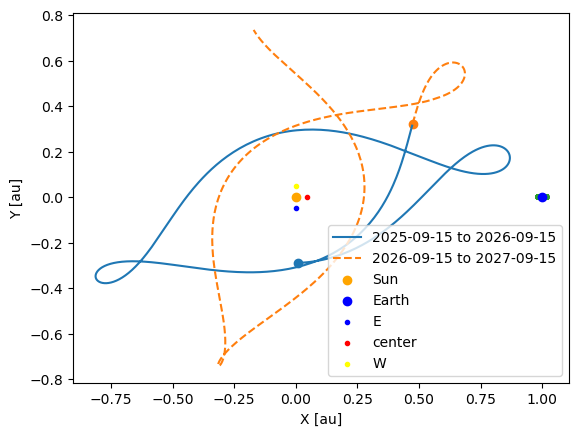

In [6]:
i = 0
linestyle = '-'
label=f'{mission_start.strftime("%Y-%m-%d")} to {mission_end.strftime("%Y-%m-%d")}'
for phase_e in [[mission_start, mission_end], [mission_end, extended_end]]:
    ind = (so_coords.obstime > phase_e[0]) & (so_coords.obstime < phase_e[1])
    if i == 1:
        linestyle = '--'
        label = f'{mission_end.strftime("%Y-%m-%d")} to {extended_end.strftime("%Y-%m-%d")}'
    plt.plot(so_coords.x[ind], so_coords.y[ind], linestyle=linestyle, label=label)
    plt.scatter(so_coords.x[ind][0], so_coords.y[ind][0], marker='o')
    i += 1
plt.xlabel('X [au]')
plt.ylabel('Y [au]')
plt.scatter(earth_coords.x, earth_coords.y, linestyle=linestyle, marker='.')

plt.scatter([0] * u.au, [0] * u.au, marker='o', color='orange', label='Sun')
plt.scatter([1] * u.au, [0] * u.au, marker='o', color='blue', label='Earth')

plt.scatter(10*eastlimb_flare_coord.x.to(u.au)[0], 10*eastlimb_flare_coord.y.to(u.au)[0], color='blue', marker='.', label='E')
plt.scatter(10*center_flare_coord.x.to(u.au)[0], 10*center_flare_coord.y.to(u.au)[0], color='red', marker='.', label='center')
plt.scatter(10*westlimb_flare_coord.x.to(u.au)[0], 10*westlimb_flare_coord.y.to(u.au)[0], color='yellow', marker='.', label='W')

plt.legend()
plt.savefig('solar_orbiter_position.pdf')
plt.show()

# Compare this with JPL Horizons data

In [7]:
so_coords_jpl = get_horizons_coord('Solar Orbiter', {'start': so_coords.obstime[0],'stop': so_coords.obstime[-1], 'step': '1d'})


INFO: Obtained JPL HORIZONS location for Solar Orbiter (spacecraft) (-144) [sunpy.coordinates.ephemeris]


In [8]:
hee_frame = HeliocentricEarthEcliptic(obstime=so_coords_jpl.obstime)

so_coords_jpl = so_coords_jpl.transform_to(hee_frame)
so_coords_jpl.representation_type = 'cartesian'

In [9]:
def coord_to_heexy(coord):
    hee_frame = HeliocentricEarthEcliptic(obstime=coord.obstime)
    coord = coord.transform_to(hee_frame)
    coord.representation_type = 'cartesian'
    return coord.y.to_value('AU'), coord.x.to_value('AU')

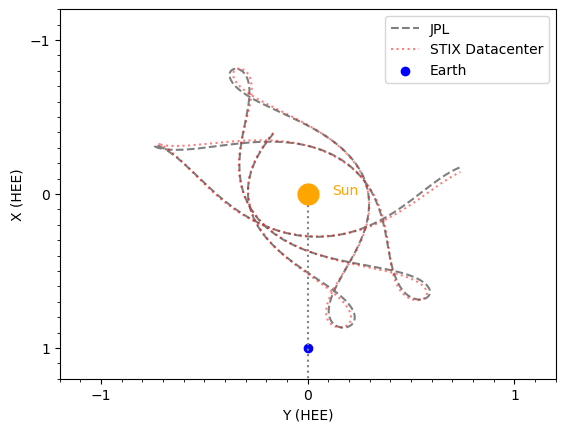

In [10]:
fig = plt.figure()
ax = fig.add_subplot()

ax.set_xlim(-1.2, 1.2)
ax.set_xlabel('Y (HEE)')
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))

ax.set_ylim(1.2, -1.2)
ax.set_ylabel('X (HEE)')
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))

ax.plot([0, 0], [0, 2], linestyle='dotted', color='gray')

ax.plot(*coord_to_heexy(so_coords_jpl), linestyle='dashed', color='gray', label='JPL')
ax.plot(*coord_to_heexy(so_coords), linestyle='dotted', color='red', alpha=0.5, label='STIX Datacenter')

ax.plot(0, 0, 'o', markersize=15, color='orange')
ax.text(0.12, 0, 'Sun', color='orange')
plt.scatter([0] * u.au, [1] * u.au, marker='o', color='blue', label='Earth')
plt.legend()
plt.show()

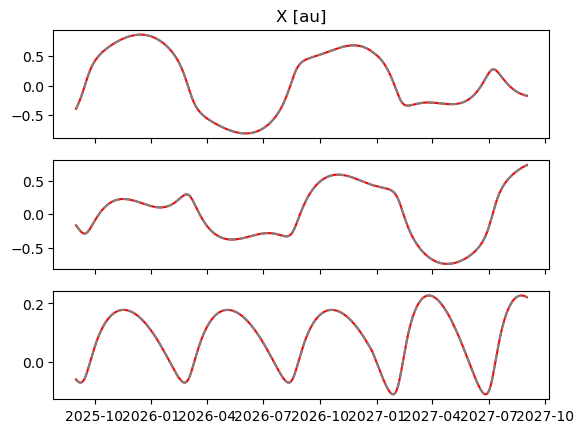

In [11]:
fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, sharex=True)
ax1.plot(so_coords.obstime.to_datetime(), so_coords.x, color='red')
ax2.plot(so_coords.obstime.to_datetime(), so_coords.y, color='red')
ax3.plot(so_coords.obstime.to_datetime(), so_coords.z, color='red')

ax1.plot(so_coords_jpl.obstime.to_datetime(), so_coords_jpl.x, linestyle='dashed', color='gray')
ax2.plot(so_coords_jpl.obstime.to_datetime(), so_coords_jpl.y, linestyle='dashed', color='gray')
ax3.plot(so_coords_jpl.obstime.to_datetime(), so_coords_jpl.z, linestyle='dashed', color='gray')

ax1.set_title('X [au]')
ax1.set_title('Y [au]')
ax1.set_title('X [au]')

plt.show()

STIX Datacenter and JPL match very with the flipped axis implemented. For the remainder of notebook use STIX data center coordinates

In [12]:
img = np.full((10, 10), np.nan)

# Define a reference coordinate and create a header using sunpy.map.make_fitswcs_header
skycoord = SkyCoord(0*u.arcsec, 0*u.arcsec, obstime=mission_start,
                    observer='earth', frame=frames.Helioprojective)
# Scale set to the following for solar limb to be in the field of view
header = sunpy.map.make_fitswcs_header(img, skycoord, scale=[220, 220]*u.arcsec/u.pixel)
# Use sunpy.map.Map to create the blank map
blank_map = sunpy.map.Map(img, header)

## Calculating Angles

### Check the astropy functions separation and position angle

In [13]:
def plot_test_angles(obs_lonlat, coord_lonlat):
    img = np.full((10, 10), np.nan)
    observer_coord = SkyCoord(obs_lonlat[0],obs_lonlat[1], 1*u.AU, frame=frames.HeliographicStonyhurst)
    coord = SkyCoord(coord_lonlat[0], coord_lonlat[1], frame=frames.HeliographicStonyhurst, observer=observer_coord)
    skycoord = SkyCoord(0*u.arcsec, 0*u.arcsec, obstime=mission_start,
                    observer=observer_coord, frame=frames.Helioprojective)
    hpc_frame = frames.Helioprojective(observer=observer_coord)
     # Define a reference coordinate and create a header using sunpy.map.make_fitswcs_header
    # Scale set to the following for solar limb to be in the field of view
    header = sunpy.map.make_fitswcs_header(img, skycoord, scale=[220, 220]*u.arcsec/u.pixel)
    # Use sunpy.map.Map to create the blank map
    blank_map = sunpy.map.Map(img, header)
    fig = plt.figure()
    ax = fig.add_subplot(projection=blank_map)
    blank_map.plot(axes=ax)
    blank_map.draw_limb(axes=ax, color="k")
    blank_map.draw_grid(axes=ax, color="k")
    ax.plot_coord(coord, 'x', label=f'{observer_coord.separation(coord):0.2f}')
    ax.set_title(f'Observer {obs_lonlat} visible: {coord.transform_to(hpc_frame).is_visible()}')
    plt.legend()
    plt.show()

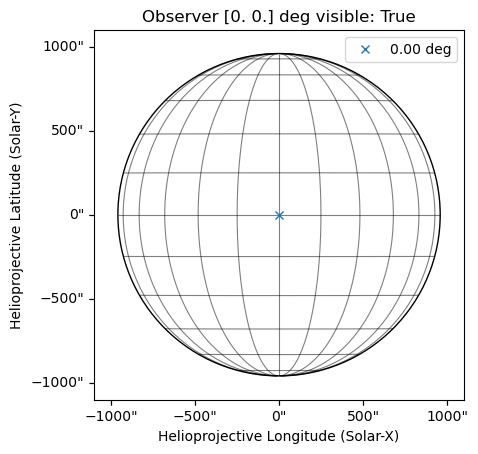

In [14]:
plot_test_angles([0, 0] * u.deg, [0, 0] * u.deg)

In [15]:
observer_coord = SkyCoord(0*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
coord = SkyCoord(0*u.arcsec, 0*u.arcsec, frame=frames.Helioprojective, observer=observer_coord)
observer_coord.separation(coord)

<Angle 0. deg>

Flare on the center of the disk has no angle with the Earth observer.

In [16]:
observer_coord = SkyCoord(0*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
coord = SkyCoord(100*u.arcsec, 0*u.arcsec, frame=frames.Helioprojective, observer=observer_coord)
hpc_frame = frames.Helioprojective(observer=observer_coord)
print(f"Separation: {observer_coord.separation(coord):0.2f} Position angle: {observer_coord.position_angle(coord).to('deg'):0.2f}, Visible:{coord.transform_to(hpc_frame).is_visible()}")

Separation: 5.96 deg Position angle: 90.00 deg, Visible:True


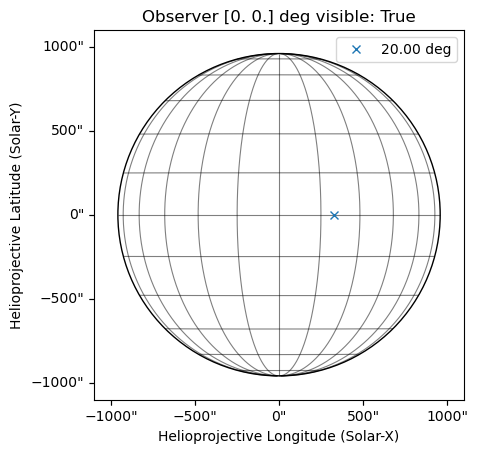

In [17]:
plot_test_angles([0, 0] * u.deg, [20, 0] * u.deg)

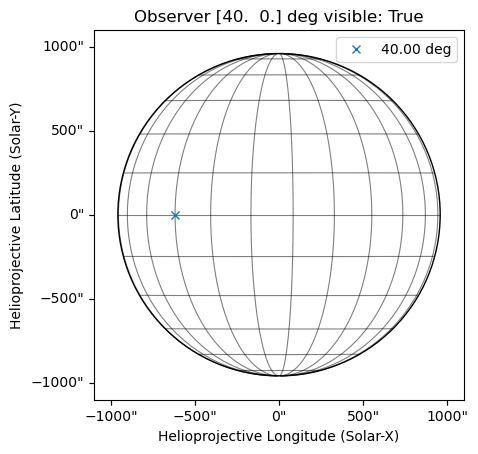

In [18]:
plot_test_angles([40, 0] * u.deg, [0, 0] * u.deg)

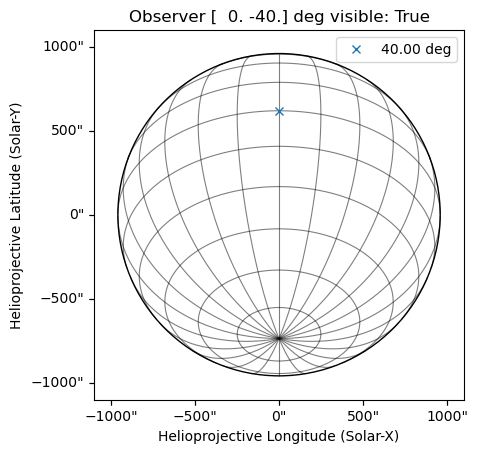

In [19]:
plot_test_angles([0, -40] * u.deg, [0, 0] * u.deg)

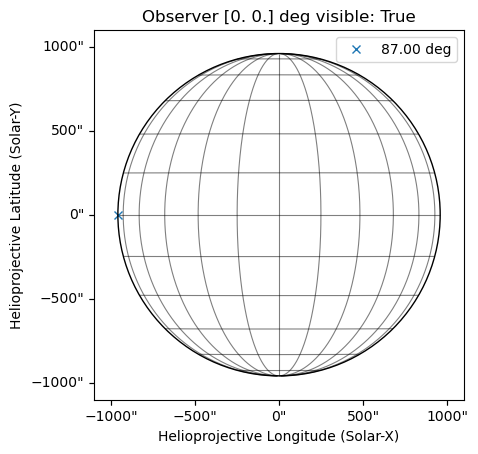

In [20]:
plot_test_angles([0, 0] * u.deg, [-87, 0] * u.deg)

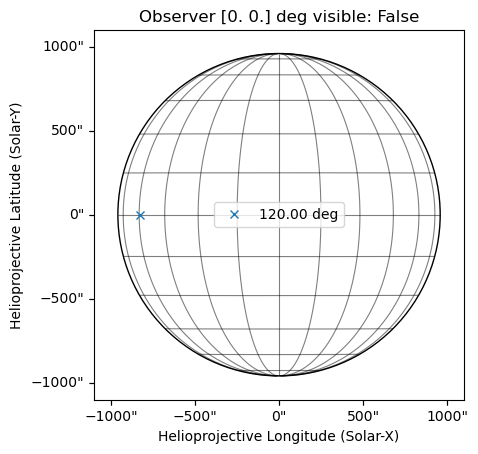

In [21]:
plot_test_angles([0, 0] * u.deg, [-120, 0] * u.deg)

In [22]:
observer_coord = SkyCoord(0*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
coord = SkyCoord(90*u.deg, 0*u.arcsec, frame=frames.HeliographicStonyhurst, observer=observer_coord)
hpc_frame = frames.Helioprojective(observer=observer_coord)
print(f"Separation: {observer_coord.separation(coord):0.2f} Position angle: {observer_coord.position_angle(coord).to('deg'):0.2f}, Visible:{coord.transform_to(hpc_frame).is_visible()}")

Separation: 90.00 deg Position angle: 90.00 deg, Visible:False


In [23]:
observer_coord = SkyCoord(0*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
coord = SkyCoord(-89*u.deg, 0*u.arcsec, frame=frames.HeliographicStonyhurst, observer=observer_coord)
hpc_frame = frames.Helioprojective(observer=observer_coord)
print(f"Separation: {observer_coord.separation(coord):0.2f} Position angle: {observer_coord.position_angle(coord).to('deg'):0.2f}, Visible:{coord.transform_to(hpc_frame).is_visible()}")

Separation: 89.00 deg Position angle: 270.00 deg, Visible:True


In [24]:
observer_coord = SkyCoord(0*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
coord = SkyCoord(-87*u.deg, 10*u.deg, frame=frames.HeliographicStonyhurst, observer=observer_coord)
hpc_frame = frames.Helioprojective(observer=observer_coord)
print(f"Separation: {observer_coord.separation(coord):0.2f} Position angle: {observer_coord.position_angle(coord).to('deg'):0.2f}, Visible:{coord.transform_to(hpc_frame).is_visible()}")

Separation: 87.05 deg Position angle: 280.01 deg, Visible:True


In [25]:
observer_coord = SkyCoord(-180*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
coord = SkyCoord(0*u.deg, 0*u.deg, frame=frames.HeliographicStonyhurst, observer=observer_coord)
hpc_frame = frames.Helioprojective(observer=observer_coord)
print(f"Separation: {observer_coord.separation(coord):0.2f} Position angle: {observer_coord.position_angle(coord).to('deg'):0.2f}, Visible:{coord.transform_to(hpc_frame).is_visible()}")

Separation: 180.00 deg Position angle: 90.00 deg, Visible:False


In [26]:
observer_coord = SkyCoord(-180*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
coord = SkyCoord(-180*u.deg, 0*u.deg, frame=frames.HeliographicStonyhurst, observer=observer_coord)
hpc_frame = frames.Helioprojective(observer=observer_coord)
print(f"Separation: {observer_coord.separation(coord):0.2f} Position angle: {observer_coord.position_angle(coord).to('deg'):0.2f}, Visible:{coord.transform_to(hpc_frame).is_visible()}")

Separation: 0.00 deg Position angle: 0.00 deg, Visible:True


In [27]:
observer1_coord = SkyCoord(0*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
observer2_coord = SkyCoord(45*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
coord = SkyCoord(45*u.deg, 0*u.deg, frame=frames.HeliographicStonyhurst, observer=observer_coord)
hpc_frame1 = frames.Helioprojective(observer=observer1_coord)
hpc_frame2 = frames.Helioprojective(observer=observer2_coord)

print(f"Separation: {observer1_coord.separation(coord):0.2f} Position angle: {observer1_coord.position_angle(coord).to('deg'):0.2f}, Visible:{coord.transform_to(hpc_frame1).is_visible()}")
print(f"Separation: {observer2_coord.separation(coord):0.2f} Position angle: {observer2_coord.position_angle(coord).to('deg'):0.2f}, Visible:{coord.transform_to(hpc_frame2).is_visible()}")

Separation: 45.00 deg Position angle: 90.00 deg, Visible:True
Separation: 0.00 deg Position angle: 0.00 deg, Visible:True


In [28]:
observer1_coord = SkyCoord(0*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
observer2_coord = SkyCoord(-90*u.deg, 0*u.deg, 1*u.AU, frame=frames.HeliographicStonyhurst)
coord = SkyCoord(-120*u.deg, 0*u.deg, frame=frames.HeliographicStonyhurst, observer=observer_coord)
hpc_frame1 = frames.Helioprojective(observer=observer1_coord)
hpc_frame2 = frames.Helioprojective(observer=observer2_coord)

print(f"Separation: {observer1_coord.separation(coord):0.2f} Position angle: {observer1_coord.position_angle(coord).to('deg'):0.2f}, Visible:{coord.transform_to(hpc_frame1).is_visible()}")
print(f"Separation: {observer2_coord.separation(coord):0.2f} Position angle: {observer2_coord.position_angle(coord).to('deg'):0.2f}, Visible:{coord.transform_to(hpc_frame2).is_visible()}")

Separation: 120.00 deg Position angle: 270.00 deg, Visible:False
Separation: 30.00 deg Position angle: 270.00 deg, Visible:True


In [29]:
so_sun_earth_angles = so_coords.separation(earth_coords)
so_sun_earth_angles_noz = so_coords_noz.separation(earth_coords)

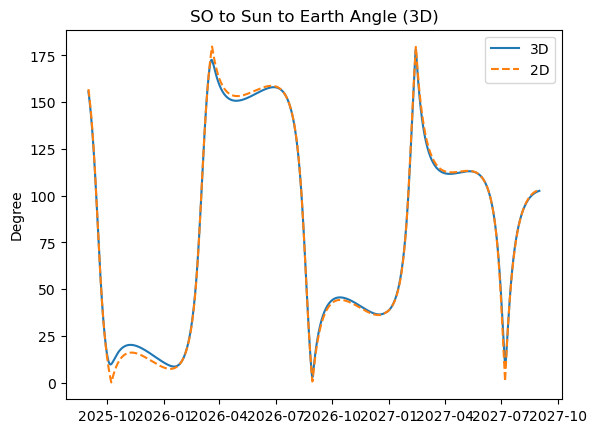

In [30]:
plt.plot(so_coords.obstime.to_datetime(), so_sun_earth_angles, label='3D')
plt.plot(so_coords.obstime.to_datetime(), so_sun_earth_angles_noz, linestyle='--', label='2D')
plt.title('SO to Sun to Earth Angle (3D)')
plt.ylabel('Degree')
plt.legend()
plt.show()

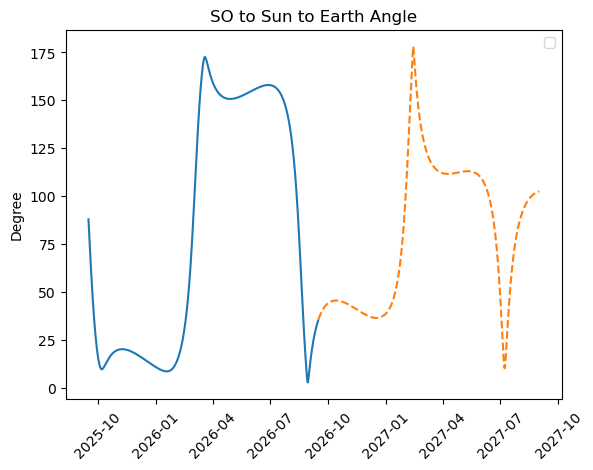

In [31]:
linestyle='-'
i = 0
for phase_e in [[mission_start, mission_end], [mission_end, extended_end]]:
    ind = (so_coords.obstime > phase_e[0]) & (so_coords.obstime < phase_e[1])
    if i == 1:
        linestyle = '--'
    plt.plot(so_coords.obstime[ind].to_datetime(), so_sun_earth_angles[ind], linestyle=linestyle)
    i += 1
plt.title('SO to Sun to Earth Angle')
plt.xticks(rotation=45)
plt.ylabel('Degree')
plt.legend()
plt.savefig('solar_orbiter_angles.pdf')
plt.show()


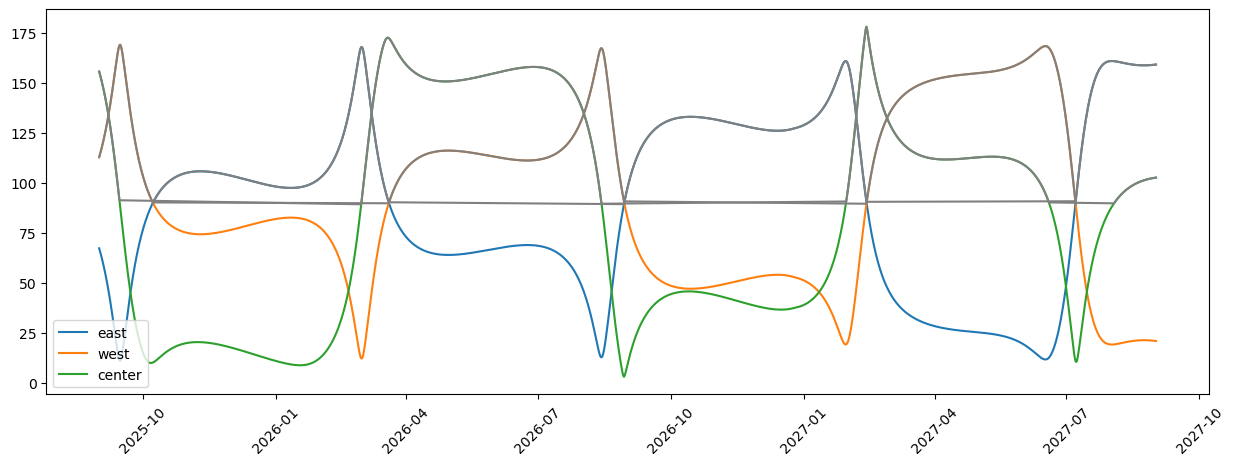

In [34]:
so_eastlimb_angles = so_coords.separation(SkyCoord(eastlimb_hpc[0], eastlimb_hpc[1], frame='heliographic_stonyhurst', obstime=so_coords.obstime))
so_center_angles = so_coords.separation(SkyCoord(center_hpc[0], center_hpc[1], frame='heliographic_stonyhurst', obstime=so_coords.obstime))
so_westlimb_angles = so_coords.separation(SkyCoord(westlimb_hpc[0], westlimb_hpc[1], frame='heliographic_stonyhurst', obstime=so_coords.obstime))

hpc_frame = frames.Helioprojective(observer=so_coords)
east_visible = SkyCoord(eastlimb_hpc[0], eastlimb_hpc[1], frame='heliographic_stonyhurst', obstime=so_coords.obstime).transform_to(hpc_frame).is_visible()
center_visible = SkyCoord(center_hpc[0], center_hpc[1], frame='heliographic_stonyhurst', obstime=so_coords.obstime).transform_to(hpc_frame).is_visible()
west_visible = SkyCoord(westlimb_hpc[0], westlimb_hpc[1], frame='heliographic_stonyhurst', obstime=so_coords.obstime).transform_to(hpc_frame).is_visible()

plt.figure(figsize=(15, 5))
plt.plot(so_coords.obstime.to_datetime(), so_eastlimb_angles.to('deg'), label='east')
plt.plot(so_coords.obstime.to_datetime(), so_westlimb_angles.to('deg'), label='west')
plt.plot(so_coords.obstime.to_datetime(), so_center_angles.to('deg'), label='center')
plt.plot(so_coords.obstime.to_datetime()[~east_visible], so_eastlimb_angles.to('deg')[~east_visible], color='grey')
plt.plot(so_coords.obstime.to_datetime()[~center_visible], so_center_angles.to('deg')[~center_visible], color='grey')
plt.plot(so_coords.obstime.to_datetime()[~west_visible], so_westlimb_angles.to('deg')[~west_visible], color='grey')

plt.xticks(rotation=45)
plt.legend()
plt.show()


East and west limb flares have the same angle but a different sign.

In [35]:
from astropy.coordinates import BarycentricMeanEcliptic
ecliptic_latitude = so_coords.transform_to(BarycentricMeanEcliptic).lat

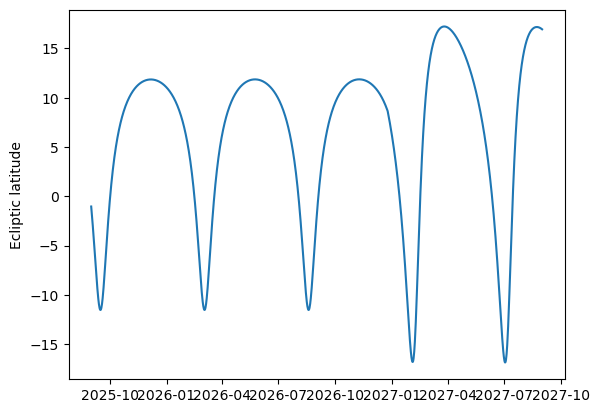

In [36]:
plt.plot(so_coords.obstime.to_datetime(), ecliptic_latitude)
plt.ylabel('Ecliptic latitude')
plt.show()


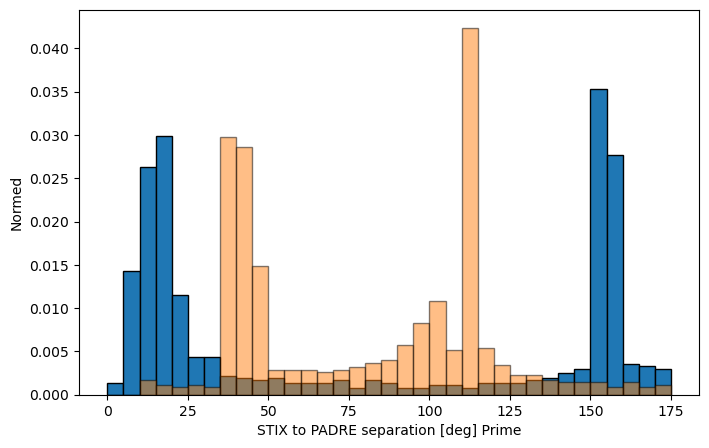

In [37]:
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.arange(0, 180, 5)
ind = (orbit_data.time > mission_start) & (orbit_data.time < mission_end)
ax.hist(so_sun_earth_angles[ind].value, 
        bins=bins, 
        density=True,
        alpha=1, 
        edgecolor="k");
ax.set_xlabel('STIX to PADRE separation [deg] Prime')
ax.set_ylabel("Normed")
ind = (orbit_data.time > mission_end) & (orbit_data.time < extended_end)
ax.hist(so_sun_earth_angles[ind].value, 
        bins=bins, 
        density=True,
        alpha=0.5, 
        edgecolor="k");
plt.savefig('solar_orbiter_angles_hist.pdf')
plt.show()

## MCMC test for number of flares

In [38]:
num_flares = 10000
flare_hpc_lat = np.random.random(num_flares) * 60 * u.deg - 30 * u.deg
flare_hpc_lon = (np.random.random(num_flares)*360) * u.deg
flare_times = TimeDelta(np.random.random(num_flares) * (mission_end - mission_start).to('s')) + mission_start
e_flare_times = TimeDelta(np.random.random(num_flares) * (extended_end - mission_end).to('s')) + mission_end

flare_coords_fixedt = SkyCoord(flare_hpc_lon, flare_hpc_lat, frame='heliographic_stonyhurst', obstime=mission_start)
flare_coords = SkyCoord(flare_hpc_lon, flare_hpc_lat, frame='heliographic_stonyhurst', obstime=flare_times)
e_flare_coords = SkyCoord(flare_hpc_lon, flare_hpc_lat, frame='heliographic_stonyhurst', obstime=e_flare_times)


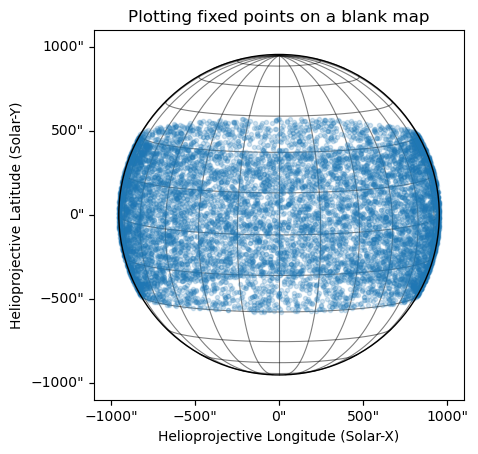

In [39]:
img = np.full((10, 10), np.nan)

# Define a reference coordinate and create a header using sunpy.map.make_fitswcs_header
skycoord = SkyCoord(0*u.arcsec, 0*u.arcsec, obstime=mission_start,
                    observer='earth', frame=frames.Helioprojective)
# Scale set to the following for solar limb to be in the field of view
header = sunpy.map.make_fitswcs_header(img, skycoord, scale=[220, 220]*u.arcsec/u.pixel)
# Use sunpy.map.Map to create the blank map
blank_map = sunpy.map.Map(img, header)

fig = plt.figure()
ax = fig.add_subplot(projection=blank_map)
blank_map.plot(axes=ax)
blank_map.draw_limb(axes=ax, color="k")
blank_map.draw_grid(axes=ax, color="k")
ax.plot_coord(flare_coords_fixedt, '.', alpha=0.2)
ax.set_title('Plotting fixed points on a blank map')
plt.show()

In [40]:
def interpolate_coords(orig_coords, new_times):
    """Interpolate a set of HeliographicStonyhurst cartesian coordinates as a function of time to a new set of times."""
    orig_ts = (orig_coords.obstime - new_times.min()).to('s').value
    new_ts = (new_times - new_times.min()).to('s').value
    interp_x = np.interp(new_ts, orig_ts, orig_coords.x.value) * orig_coords.x.unit
    interp_y = np.interp(new_ts, orig_ts, orig_coords.y.value) * orig_coords.y.unit
    interp_z = np.interp(new_ts, orig_ts, orig_coords.z.value) * orig_coords.z.unit
    return SkyCoord(interp_x, interp_y, interp_z, frame='heliographic_stonyhurst', representation_type='cartesian', obstime=new_times)

Found the coords of SO and Earth for each flare time

In [41]:
interp_so_coords = interpolate_coords(so_coords, flare_times)
interp_earth_coords = interpolate_coords(earth_coords, flare_times)

In [42]:
hpc_frame = frames.Helioprojective(observer='earth', obstime=flare_coords.obstime)
hpc_flare_coords = flare_coords.transform_to(hpc_frame)
print(f"Percent of flare visible from Earth: {np.sum(hpc_flare_coords.is_visible()) / len(hpc_flare_coords) * 100}%")


Percent of flare visible from Earth: 49.53%


In [43]:
hpc_so_frame = frames.Helioprojective(observer=interp_so_coords, obstime=flare_coords.obstime)
hpc_so_flare_coords = flare_coords.transform_to(hpc_so_frame)
print(f"Percent of flare visible from SO: {np.sum(hpc_so_flare_coords.is_visible()) / len(hpc_so_flare_coords) * 100}%")

Percent of flare visible from SO: 50.43%


In [44]:
visible_both = hpc_so_flare_coords.is_visible() * hpc_flare_coords.is_visible()
print(f"Percent of events visible by both {np.sum(visible_both) / len(visible_both) * 100}%")

Percent of events visible by both 27.639999999999997%


In [ ]:
def is_visible(coords, observer1, observer2):
    hpc_frame1 = frames.Helioprojective(observer=observer1, obstime=coords.obstime)
    hpc1_coords = coords.transform_to(hpc_frame1)
    vis1 = hpc1_coords.is_visible()
    hpc_frame2 = frames.Helioprojective(observer=observer2, obstime=coords.obstime)
    hpc2_coords = coords.transform_to(hpc_frame2)
    vis2 = hpc2_coords.is_visible()
    return vis1 * vis2

In [46]:
visible_both = is_visible(flare_coords, interp_earth_coords, interp_so_coords)
print(f"Percent of events visible by both {np.sum(visible_both) / len(visible_both) * 100}%")

Percent of events visible by both 27.58%


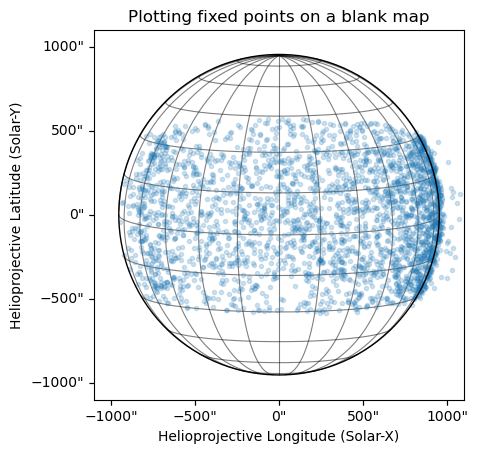

In [47]:
fig = plt.figure()
ax = fig.add_subplot(projection=blank_map)
blank_map.plot(axes=ax)
blank_map.draw_limb(axes=ax, color="k")
blank_map.draw_grid(axes=ax, color="k")
ax.plot_coord(flare_coords[visible_both], '.', alpha=0.2)
ax.set_title('Plotting fixed points on a blank map')
plt.show()

In [48]:
so_flare_angles = interp_so_coords.separation(flare_coords)
earth_flare_angles = interp_earth_coords.separation(flare_coords)

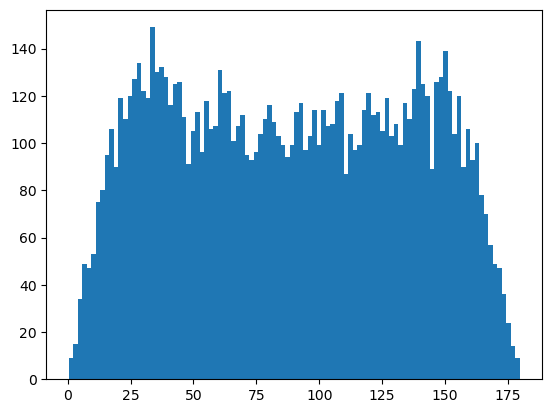

In [49]:
plt.hist(so_flare_angles, bins=100);
plt.show()

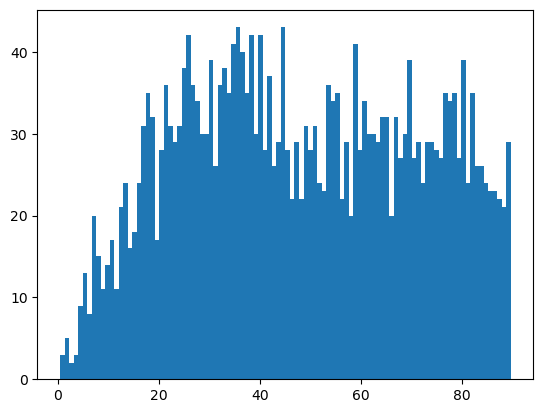

In [50]:
plt.hist(so_flare_angles[visible_both], bins=100);
plt.show()

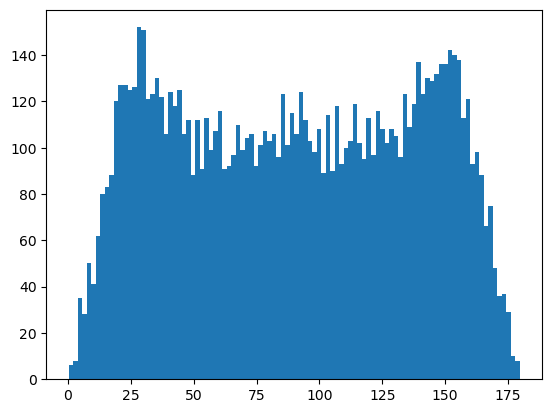

In [51]:
plt.hist(earth_flare_angles, bins=100);
plt.show()

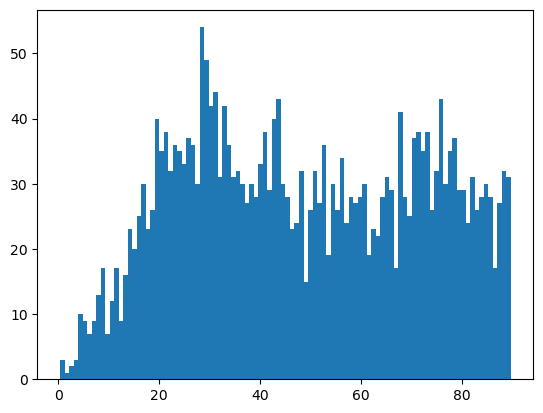

In [52]:
plt.hist(earth_flare_angles[visible_both], bins=100);
plt.show()

# Anisotropy simulation from Jeffreys et al.

This array contains the information shown in Figure 5 in https://ui.adsabs.harvard.edu/abs/2024arXiv240116032J/abstract but for every simulated viewing angle (also, the published version should appear sometime tomorrow). The structure contains:

EE_ANI                 FLOAT                   Array[5]
OBS_THETA       FLOAT                   Array[9]
EPH                       FLOAT                   Array[19]
EEPH                    FLOAT                   Array[19]
HXR_TOT             FLOAT                   Array[5, 19, 9]
HXR_PRIM          FLOAT                   Array[5, 19, 9]

ee_ani: chosen electron anisotropy from beamed to isotropic (Δμ in the paper).
obs_theta: observer viewing angle in degrees from 0 to 80 degrees.
Eph: average photon energy [keV].
eEph: photon energy (half) bin width [keV].
hxr_tot: total observed photon flux (spectra) including primary and albedo component. Array format (anisotropy, energy, angle).
hxr_prim: primary only photon flux (spectra). Array format (anisotropy, energy, angle).

In the paper, we define HXR directivity as the ratio of flux spectra (small viewing angle/large viewing angle).
Electron information (also in the paper): Footpoint injection with electron spectral index of δFP = 2 (footpoint), an electron high-energy cutoff of EH = 150 keV, a loop tilt of τ = 0Ο and Φ=90Ο which corresponds to a loop with footpoints oriented perpendicular to the direction from the disk centre to the flare location.

Please let me know if you want any other simulation data from the paper or any different simulations not shown in the paper.
If anything looks strange, let me know as I made it quickly this morning between meetings.

In [53]:
from scipy.interpolate import RegularGridInterpolator

In [54]:
anisotropy = readsav('hxr_dir_str.sav')
anisotropy['hxr_dir_str'].dtype

dtype((numpy.record, [(('ee_ani', 'EE_ANI'), 'O'), (('obs_theta', 'OBS_THETA'), 'O'), (('eph', 'EPH'), 'O'), (('eeph', 'EEPH'), 'O'), (('hxr_tot', 'HXR_TOT'), 'O'), (('hxr_prim', 'HXR_PRIM'), 'O')]))

In [55]:
view_angle = np.array(anisotropy['hxr_dir_str']['obs_theta'][0]) * u.deg
view_angle

<Quantity [ 0.      , 10.      , 20.      , 30.      , 40.      ,
           50.000004, 60.      , 70.      , 80.      ] deg>

In [56]:
energies = np.array(anisotropy['hxr_dir_str']['eph'][0]) * u.keV
energies

<Quantity [ 10.637774,  11.951287,  13.351189,  14.86128 ,  16.511929,
            18.341866,  20.400486,  22.75081 ,  25.473215,  28.670227,
            32.472626,  37.04722 ,  42.60679 ,  49.422745,  57.84128 ,
            68.30399 ,  81.374146,  97.7702  , 118.408646] keV>

In [57]:
energies_bin = np.array(anisotropy['hxr_dir_str']['eeph'][0]) * u.keV
energies_bin

<Quantity [ 0.63777447,  0.67573833,  0.7241626 ,  0.78593016,  0.86471844,
            0.96521664,  1.0934057 ,  1.256918  ,  1.4654865 ,  1.7315254 ,
            2.0708714 ,  2.5037231 ,  3.0558472 ,  3.760109  ,  4.658428  ,
            5.804283  ,  7.2658653 ,  9.130199  , 11.50824   ] keV>

In [58]:
photon_flux = np.array(anisotropy['hxr_dir_str']['hxr_tot'][0])
photon_flux.shape

(9, 19, 5)

In [59]:
mu = np.array(anisotropy['hxr_dir_str']['EE_ANI'][0])
mu

array([  0.1,   0.5,   1. ,   4. , 100. ], dtype='>f4')

Fit the photon_flux data to enable different view angles

In [60]:
x = view_angle.value
y = energies.value
z = mu
f = RegularGridInterpolator((x, y, z), photon_flux)

In [61]:
x = view_angle[0].value
y = energies.value
z = mu[0]
xg, yg, zg = np.meshgrid(x, y, z, indexing='ij')
pts = np.vstack([xg, yg, zg])[:,:,0].transpose()
f(pts)

array([9.77501404e+02, 7.67443787e+02, 6.27737671e+02, 5.17670715e+02,
       4.13292664e+02, 3.31492249e+02, 2.56755981e+02, 1.96190292e+02,
       1.41045502e+02, 9.82387772e+01, 6.55589523e+01, 3.95776100e+01,
       2.39373341e+01, 1.23386574e+01, 6.17550278e+00, 2.40266585e+00,
       8.78763020e-01, 1.32196277e-01, 2.04852540e-02])

Now check that our fit matches the data

In [62]:
def plot_anisotropy_fitdata(angles_i):
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, this_mu in enumerate(mu):
        xrayflux1 = photon_flux[angles_i[0], :, i]
        xrayflux2 = photon_flux[angles_i[1], :, i]
        directivity = xrayflux1 / xrayflux2
        ax.step(energies, directivity, label=f'data mu={this_mu:0.2f}')
        x = view_angle[angles_i[0]].value
        y = energies.value
        z = mu[0]
        xg, yg, zg = np.meshgrid(x, y, z, indexing='ij')
        pts = np.vstack([xg, yg, zg])[:,:,0].transpose()
        xrayflux1 = f(pts)
        x = view_angle[angles_i[1]].value
        y = energies.value
        z = mu[0]
        xg, yg, zg = np.meshgrid(x, y, z, indexing='ij')
        pts = np.vstack([xg, yg, zg])[:,:,0].transpose()
        xrayflux2 = f(pts)
        directivity = xrayflux1 / xrayflux2
        ax.step(energies, directivity, label=f'fit mu={this_mu:0.2f}', linestyle='--')
    ax.set_xlabel('Energy [keV]')
    ax.set_title(f"{view_angle[angles_i[0]]:0.2f} / {view_angle[angles_i[1]]:0.2f}")
    ax.legend()

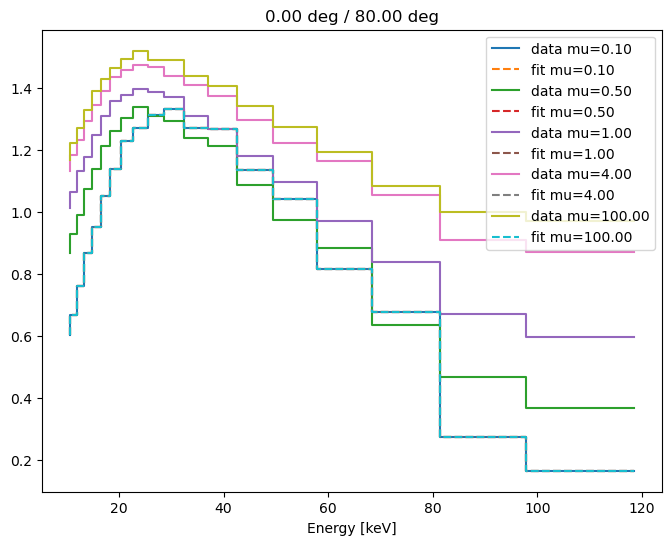

In [63]:
plot_anisotropy_fitdata([0, 8])

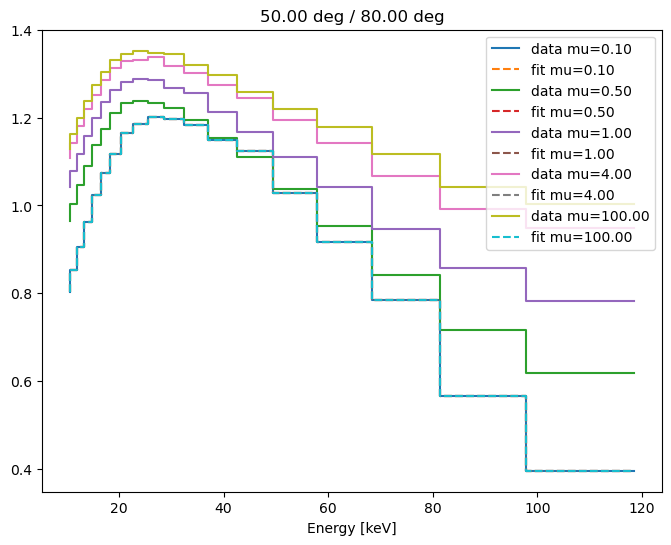

In [64]:
plot_anisotropy_fitdata([5, 8])

In [65]:
def get_xray_spectrum(angle, mu):
    x = angle
    y = energies.value
    z = mu
    xg, yg, zg = np.meshgrid(x, y, z, indexing='ij')
    pts = np.vstack([xg, yg, zg])[:,:,0].transpose()
    xrayflux = f(pts)
    return Spectrum1D(flux=xrayflux * u.ct, spectral_axis=energies)

In [66]:
def get_xray_specarray(angle, mu):
    x = angle
    y = energies.value
    z = mu
    xg, yg, zg = np.meshgrid(x, y, z, indexing='ij')
    pts = np.vstack([xg, yg, zg])[:,:,0].transpose()
    xrayflux = f(pts)
    return xrayflux

In [67]:
spec1 = get_xray_spectrum(12, 0.11)
spec2 = get_xray_spectrum(32, 0.11)

Text(0.5, 0, 'Energy [keV]')

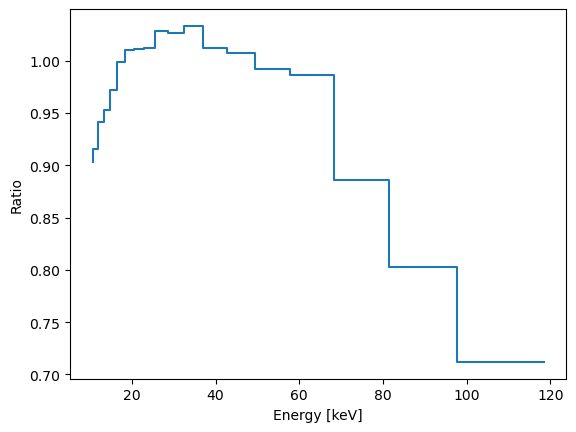

In [68]:
plt.step(spec1.spectral_axis, spec1.flux / spec2.flux)
plt.ylabel('Ratio')
plt.xlabel('Energy [keV]')

## Prime Mission

In [69]:
mission_flag = (flare_coords.obstime > mission_start) * (flare_coords.obstime < mission_end)
these_flare_coords = flare_coords[mission_flag]
these_so_coords = interp_so_coords[mission_flag]
these_earth_coods = interp_earth_coords[mission_flag]

visible_flag = is_visible(these_flare_coords, these_so_coords, these_earth_coods)

these_flare_coords = flare_coords[visible_flag]
these_so_coords = interp_so_coords[visible_flag]
these_earth_coods = interp_earth_coords[visible_flag]

earth_angle = these_earth_coods.separation(these_flare_coords)
so_angle = these_so_coords.separation(these_flare_coords)

# remove angles that are too large for the jeffreys data
good_ind = (earth_angle < 80 * u.deg) & (so_angle < 80 * u.deg)
earth_angle = earth_angle[good_ind]
so_angle = so_angle[good_ind]

In [70]:
spec_array = np.zeros((2, len(mu), len(energies), len(earth_angle)))
for i, this_mu in enumerate(mu):
    for j, (this_angle, that_angle) in enumerate(zip(earth_angle, so_angle)):
        if this_angle > that_angle:
            spec_array[0, i, :, j] = get_xray_specarray(this_angle.value, this_mu)
            spec_array[1, i, :, j] = get_xray_specarray(that_angle.value, this_mu)
        else:
            spec_array[1, i, :, j] = get_xray_specarray(this_angle.value, this_mu)
            spec_array[0, i, :, j] = get_xray_specarray(that_angle.value, this_mu)

In [71]:
from astropy.table import Table

In [72]:
summary_flares = Table.read('../summary_flare.csv')
summary_flares

goes class,Cycle 24 2025-09,Cycle 25 2025-09,Cycle 24 2026-09,Cycle 25 2026-09
str2,float64,float64,float64,float64
C,1900.0,2919.0,1089.0,1914.0
M,188.0,368.0,89.0,154.0
M5,24.0,31.0,5.0,16.0
X,15.0,12.0,1.0,7.0


In [109]:
energy_range = (energies > 20 * u.keV) * (energies > 50 * u.keV)
energy_range

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False,  True,  True,  True,  True,
        True])

In [160]:
mu_index = 0
directivity_spectrum = spec_array[1, mu_index, :, :] / spec_array[0, mu_index, :, :]
ebin = (energies > 20 * u.keV) * (energies < 40 * u.keV)
data = np.sum(directivity_spectrum[ebin, :], axis=0) / np.sum(ebin)
bins = np.arange(1, 1.6, 0.1)
hist_counts, bin_edges = np.histogram(data, bins=bins, weights=100 * np.ones(len(data)) / len(data))


In [161]:
hist_counts

array([93.89692586,  6.10307414,  0.        ,  0.        ,  0.        ,
        0.        ])

In [181]:
from matplotlib.ticker import PercentFormatter
def plot_anisotropy(spec_array, mu_index, num_flares1, num_flares2):
    energy_hi = 40 * u.keV
    energy_low = 20 * u.keV
    ebin = (energies > energy_low) * (energies < energy_hi)
    bins = np.arange(1, 1.6, 0.1)
    directivity_spectrum = spec_array[1, mu_index, :, :] / spec_array[0, mu_index, :, :]
    fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=1, ncols=4, figsize=(16, 5))
    for i in range(len(earth_angle)):
        ax1.step(energies, directivity_spectrum[:, i], alpha=0.01, color='black')
    ax1.axvspan(energy_low.value, energy_hi.value)
    ax1.set_title(f"mu={mu[mu_index]:0.2f}")
    data = np.sum(directivity_spectrum[ebin, :], axis=0) / np.sum(ebin)
    ax2.hist(data, bins=bins,  weights=np.ones(len(data)) / len(data))
    ax2.yaxis.set_major_formatter(PercentFormatter(1))

    hist_counts, bin_edges = np.histogram(data, bins=bins, weights=num_flares1 * np.ones(len(data)) / len(data))
    label = f">=20% {np.sum(hist_counts[2:]):0.0f} >=10% {np.sum(hist_counts[1:]):0.0f}"
    ax3.hist(data, bins=bins,  weights=num_flares1 * np.ones(len(data)) / len(data), label=label)
    ax3.set_ylabel('Number of M class flares')
    ax3.legend()
    hist_counts, bin_edges = np.histogram(data, bins=bins, weights=num_flares2 * np.ones(len(data)) / len(data))
    label = f">=20% {np.sum(hist_counts[2:]):0.0f} >=10% {np.sum(hist_counts[1:]):0.0f}"
    ax4.hist(data, bins=bins,  weights=num_flares2 * np.ones(len(data)) / len(data), label=label)
    ax4.set_ylabel('Number of >M5 class flares')
    ax4.legend()

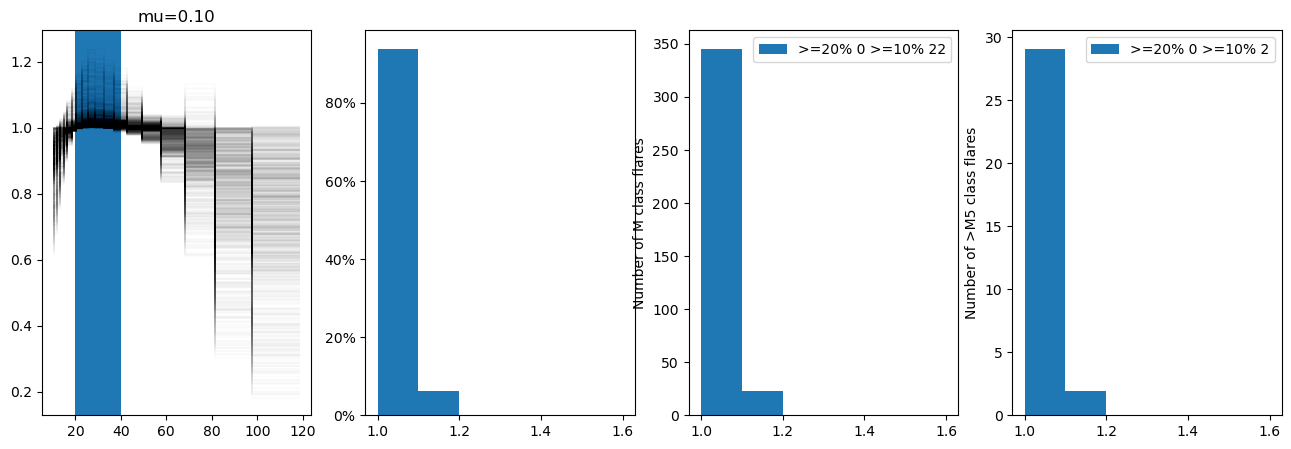

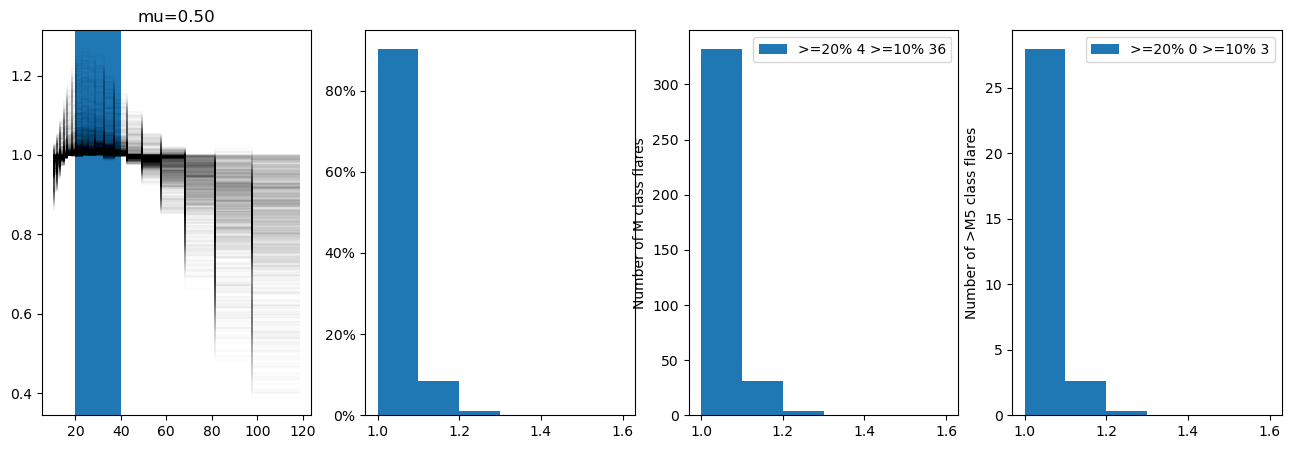

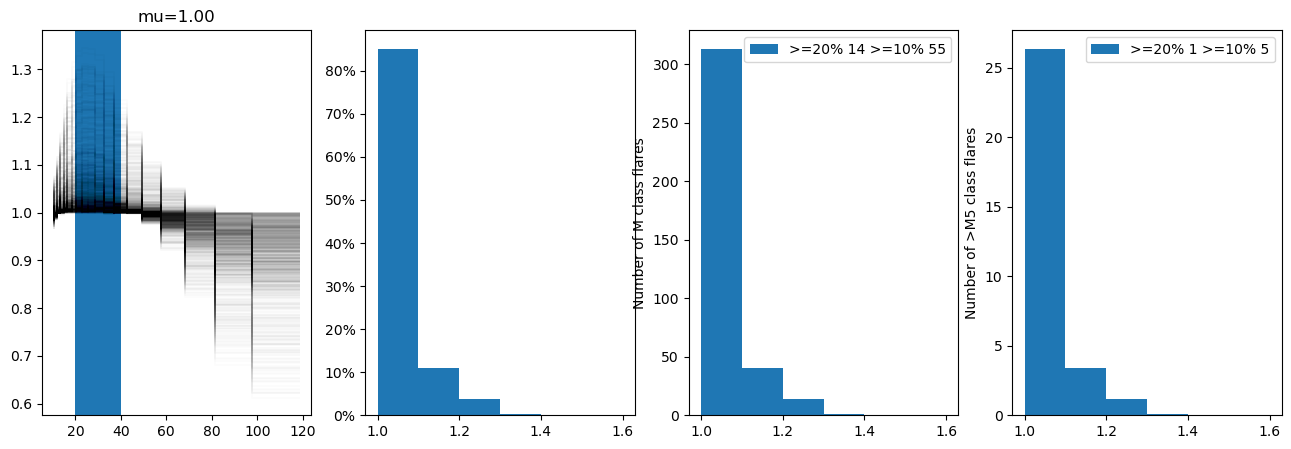

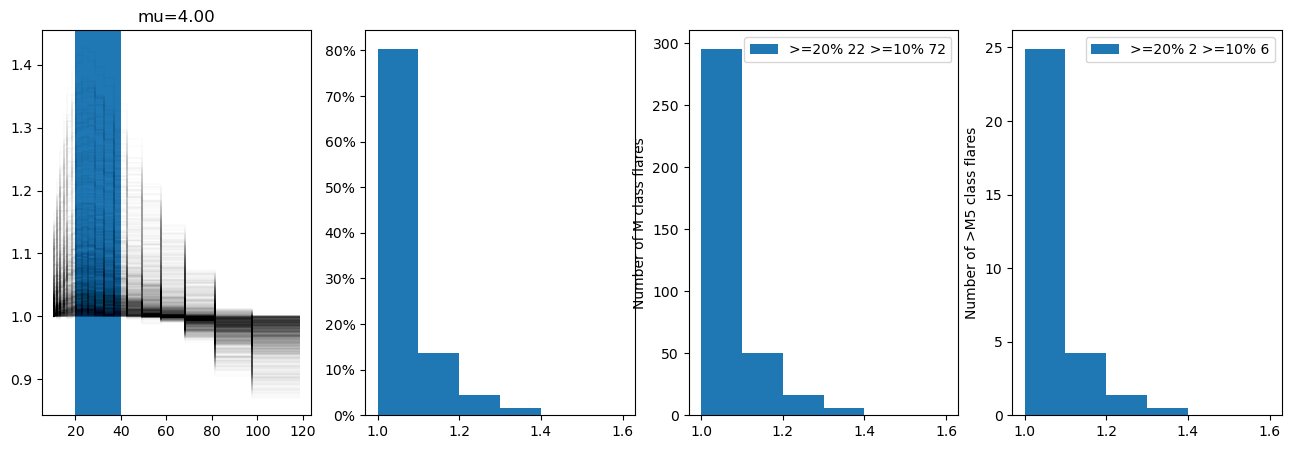

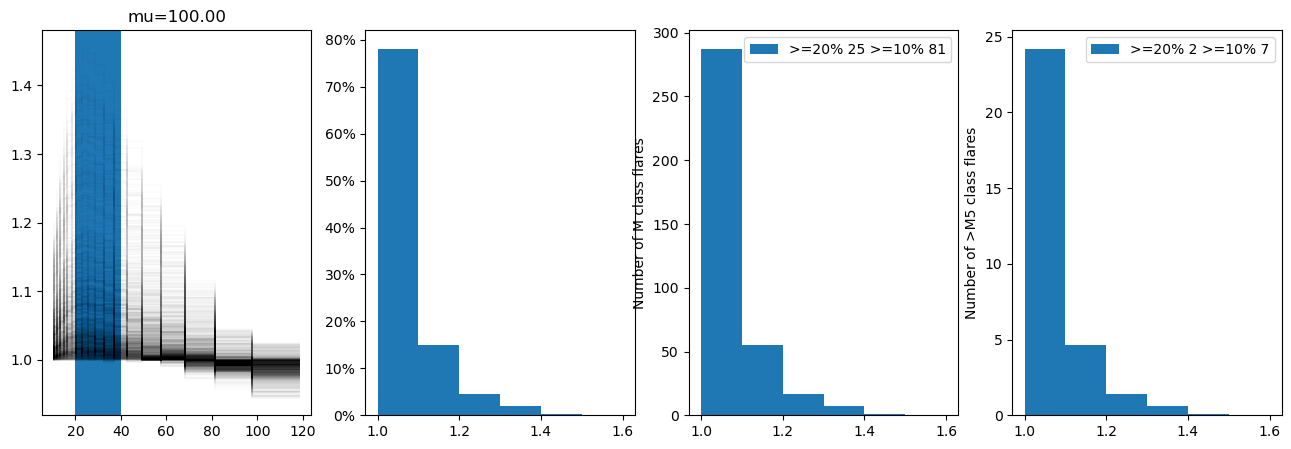

In [182]:
for i_mu in range(5):
    plot_anisotropy(spec_array, i_mu, summary_flares['Cycle 25 2025-09'][1], summary_flares['Cycle 25 2025-09'][2])

# Extended Mission

In [183]:
mission_flag = (e_flare_coords.obstime > mission_end) * (e_flare_coords.obstime < extended_end)
these_flare_coords = e_flare_coords[mission_flag]
these_so_coords = interpolate_coords(so_coords, these_flare_coords.obstime)
these_earth_coods = interpolate_coords(earth_coords, e_flare_coords.obstime)

visible_flag = is_visible(these_flare_coords, these_so_coords, these_earth_coods)

these_flare_coords = flare_coords[visible_flag]
these_so_coords = interp_so_coords[visible_flag]
these_earth_coods = interp_earth_coords[visible_flag]

earth_angle = these_earth_coods.separation(these_flare_coords)
so_angle = these_so_coords.separation(these_flare_coords)

# remove angles that are too large for the jeffreys data
good_ind = (earth_angle < 80 * u.deg) & (so_angle < 80 * u.deg)
earth_angle = earth_angle[good_ind]
so_angle = so_angle[good_ind]

In [184]:
espec_array = np.zeros((2, len(mu), len(energies), len(earth_angle)))
for i, this_mu in enumerate(mu):
    for j, (this_angle, that_angle) in enumerate(zip(earth_angle, so_angle)):
        if this_angle > that_angle:
            espec_array[0, i, :, j] = get_xray_specarray(this_angle.value, this_mu)
            espec_array[1, i, :, j] = get_xray_specarray(that_angle.value, this_mu)
        else:
            espec_array[1, i, :, j] = get_xray_specarray(this_angle.value, this_mu)
            espec_array[0, i, :, j] = get_xray_specarray(that_angle.value, this_mu)

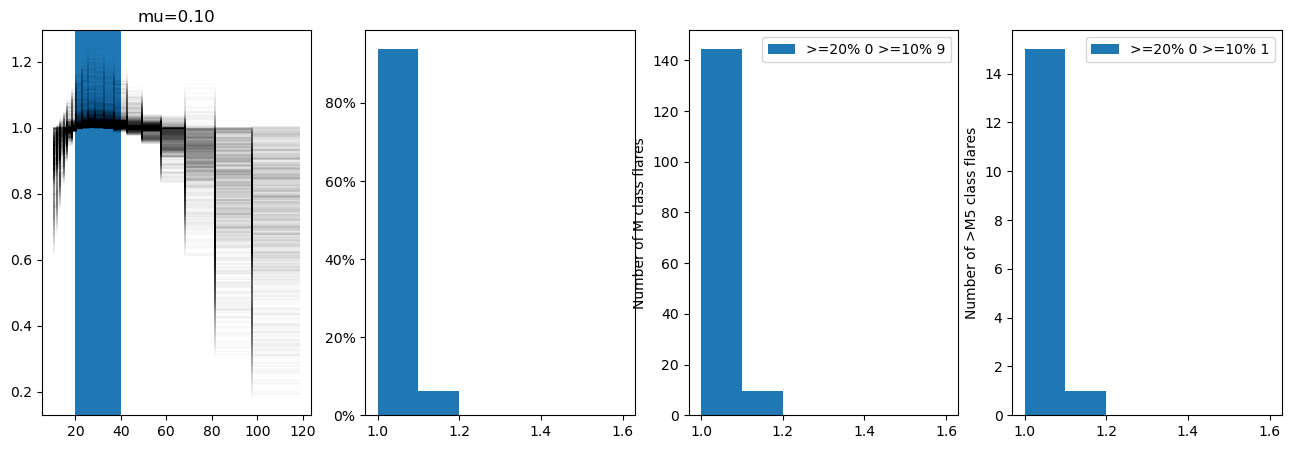

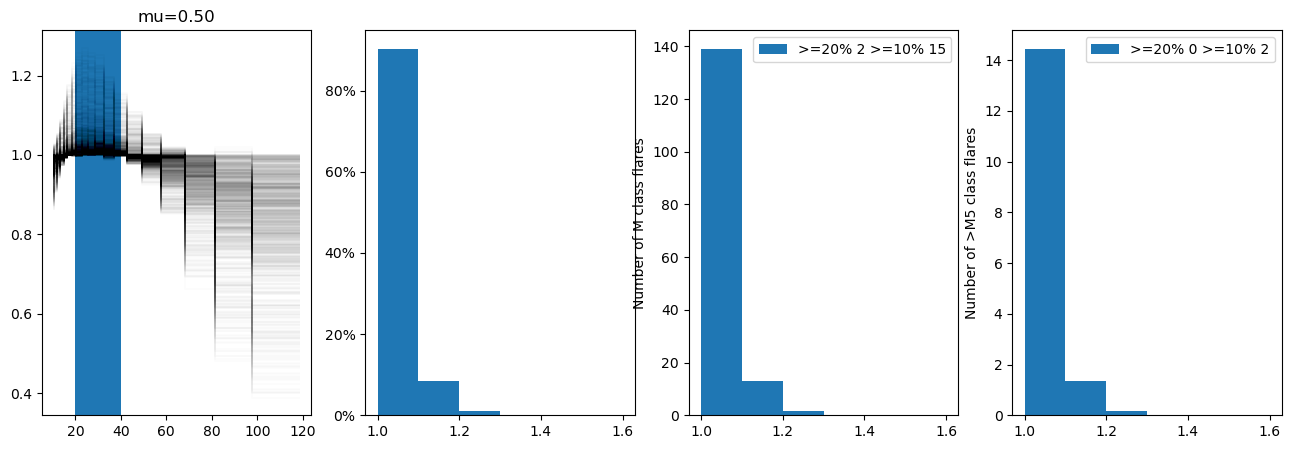

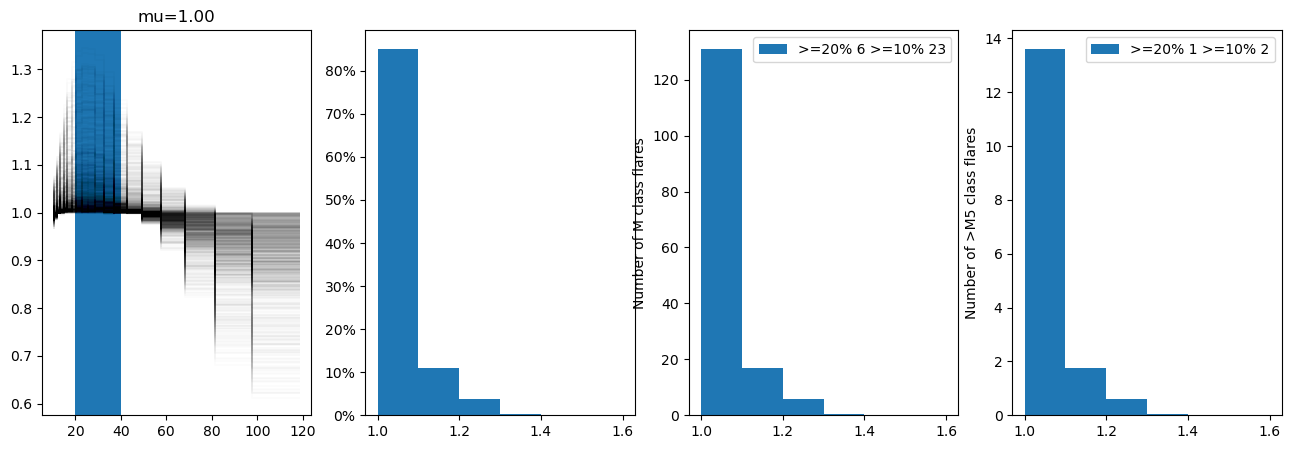

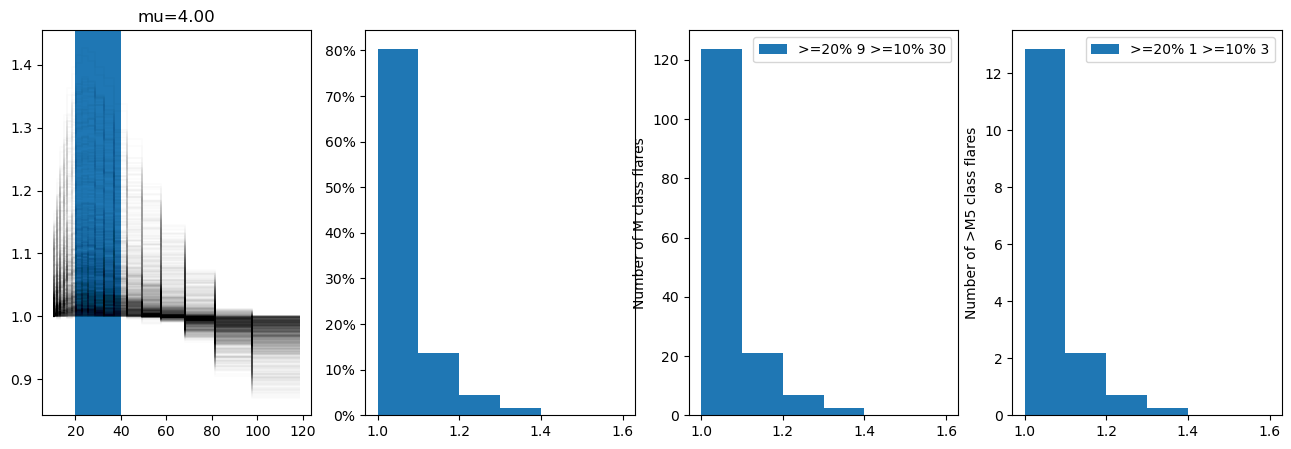

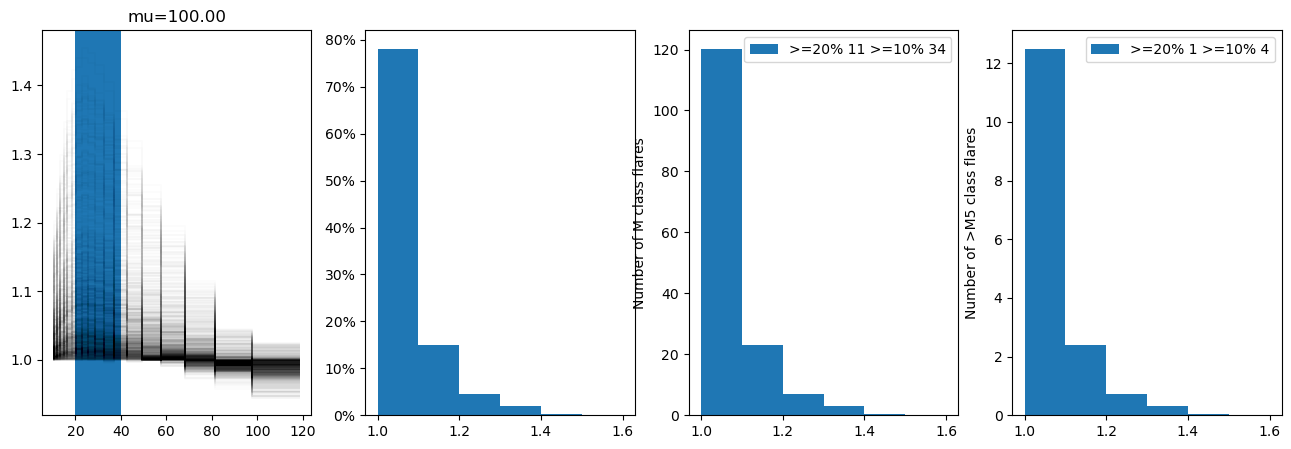

In [185]:
for i_mu in range(5):
    plot_anisotropy(spec_array, i_mu, summary_flares['Cycle 25 2026-09'][1], summary_flares['Cycle 25 2026-09'][2])